---
# <div align="center"><font color='red'>  </font></div>
# <div align="center"><font color='red'> COSC2779 | Deep Learning  </font></div>
## <div align="center"> <font color='red'> Week 9 Lecture Example: **Representation Learning — Self-Supervision & LoRA**</font></div>
---

This week is about **representations**: learning useful features without labels, and then **adapting** a pre-trained model cheaply. As in Weeks 7–8 we build the moving parts from scratch on a tiny, controllable problem, so the *idea* is visible rather than raw performance.

Three parts:
1. **Static vs contextual embeddings** — why a Transformer embedding beats a GloVe-style one on the classic *bank* example.
2. **Self-supervised learning** — pre-train a small Transformer with **masked-token prediction** (no labels), then show its representation transfers via a linear probe.
3. **LoRA-style fine-tuning** — adapt that frozen encoder with feature extraction, full fine-tuning, and **LoRA from scratch**, comparing accuracy vs trainable parameters.

# Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.linear_model import LogisticRegression

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)
torch.manual_seed(0); np.random.seed(0)

def n_params(model, trainable_only=True):
    return sum(p.numel() for p in model.parameters() if (p.requires_grad or not trainable_only))

Using device: cuda


# Part 1 — Static vs contextual embeddings

A **static** embedding (word2vec / GloVe) gives each word *one fixed vector*, so both senses of *bank* collapse to the same point. A **contextual** embedding from a pre-trained Transformer (BERT) computes the vector *from the whole sentence*, so *bank* gets different vectors in "river bank" vs "savings bank".


In [2]:
!pip install -q gensim transformers

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 78.9 MB/s eta 0:00:00:00:0100:01


### GloVe: one fixed vector per word

In [3]:
try:
    import gensim.downloader as api
    glove = api.load("glove-wiki-gigaword-50")   # ~66 MB download (first time)
    print("nearest neighbours of 'bank' (GloVe — senses are mixed):")
    for w, s in glove.most_similar("bank", topn=15):
        print(f"  {w:12s} {s:.3f}")
    print("\nnearest neighbours of 'java':")
    for w, s in glove.most_similar("java", topn=8):
        print(f"  {w:12s} {s:.3f}")
except Exception as e:
    print("[skipped] GloVe demo needs `gensim` + internet. Run locally to see it.")
    print("reason:", type(e).__name__, e)

[==================================================] 100.0% 66.0/66.0MB downloaded
nearest neighbours of 'bank' (GloVe — senses are mixed):
  banks        0.870
  securities   0.800
  banking      0.797
  investment   0.785
  exchange     0.781
  financial    0.767
  credit       0.765
  lender       0.752
  capital      0.738
  brokerage    0.737
  currency     0.736
  investments  0.734
  funds        0.728
  fund         0.727
  assets       0.724

nearest neighbours of 'java':
  semarang     0.715
  surabaya     0.710
  applets      0.691
  remote       0.685
  applet       0.680
  api          0.678
  wii          0.658
  jvm          0.656


Look at what "nearest neighbours" means for a **static** embedding — one fixed vector per word:

**`bank`** → *banks, securities, banking, investment, exchange, financial, credit, lender, capital, brokerage, currency, funds, assets*

Every neighbour is the **finance** sense. The river/shore meaning is nowhere to be seen. GloVe's single vector doesn't blend both senses here — it collapses onto the **dominant** one, because "bank" appears far more often in a financial context in the training corpus. So the geographic sense is effectively lost, and there is no way for the vector to switch to it depending on the sentence.

**`java`** → *semarang, surabaya, applets, remote, applet, api, wii, jvm*

Here the single vector is pulled between **two unrelated senses at once**: the Indonesian island (*semarang, surabaya* — both cities on Java) and the programming language (*applets, applet, api, jvm*). Neither sense is cleanly represented; they interfere in one point in space.

**The common problem:** whether the static vector collapses onto the dominant sense (`bank`) or muddles several senses together (`java`), it is **one fixed vector regardless of context**. It cannot become "river bank" in one sentence and "savings bank" in another. That is exactly the limitation a contextual model removes.

### BERT: the same word, different vectors by context

Where GloVe gave *one fixed vector* per word, BERT computes a **new vector every time a word appears**, shaped by the surrounding sentence. Here we test that directly on the word **"bank"**.

We take four sentences — two using the *river* sense and two the *finance* sense — and, for each, pull out BERT's vector for the **"bank" token specifically**. We then compare all four vectors with **cosine similarity** and draw the result as a heatmap.

**What each step does:**
- **Tokenise + encode** the sentence and read `last_hidden_state` — one contextual vector per token (this is the sentence-aware representation, not a lookup).
- **Locate "bank"** among the tokens and take *its* vector (averaging the pieces if the tokenizer split it).
- **Normalise and take dot products** between the four "bank" vectors — cosine similarity, where 1.0 = identical direction, lower = more different.

**What to look for in the heatmap:** the two *river* sentences should be similar to each other, and the two *finance* sentences similar to each other, but **river-vs-finance pairs should be clearly lower**. If GloVe were doing this, all four would be identical (one fixed vector); with BERT they split into two groups — proof that the same word gets **different vectors in different contexts**. That contextual representation is exactly what Part 2 then learns from scratch.

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


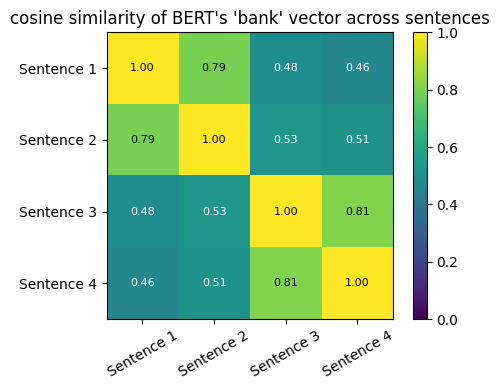

Same-sense pairs are close; cross-sense pairs are clearly lower —
the contextual vector for 'bank' depends on the sentence.


In [4]:
def bert_bank_demo():
    import torch as T
    from transformers import AutoTokenizer, AutoModel
    tok = AutoTokenizer.from_pretrained("bert-base-uncased")
    model = AutoModel.from_pretrained("bert-base-uncased").eval()

    def word_vector(sentence, word):
        enc = tok(sentence, return_tensors="pt")
        with T.no_grad():
            out = model(**enc).last_hidden_state[0]      # (tokens, 768)
        ids = enc["input_ids"][0]
        wid = tok.convert_tokens_to_ids(word)
        pos = (ids == wid).nonzero(as_tuple=True)[0]
        return out[pos].mean(0)                          # avg if word split

    sents = [
        "i sat on the river bank and watched the water",
        "we went fishing by the bank of the river",
        "i deposited the cheque at the bank downtown",
        "the bank approved my loan application",
    ]
    vecs = T.stack([word_vector(s, "bank") for s in sents])
    vecs = vecs / vecs.norm(dim=1, keepdim=True)
    sim = (vecs @ vecs.T).numpy()

    fig, ax = plt.subplots(figsize=(5, 4))
    im = ax.imshow(sim, cmap="viridis", vmin=0, vmax=1)
    labels = ["Sentence 1", "Sentence 2", "Sentence 3", "Sentence 4"]
    ax.set_xticks(range(4)); ax.set_xticklabels(labels, rotation=30)
    ax.set_yticks(range(4)); ax.set_yticklabels(labels)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f"{sim[i,j]:.2f}", ha="center", va="center",
                    color="white" if sim[i,j] < 0.7 else "black", fontsize=8)
    ax.set_title("cosine similarity of BERT's 'bank' vector across sentences")
    plt.colorbar(im); plt.tight_layout(); plt.show()
    print("Same-sense pairs are close; cross-sense pairs are clearly lower —")
    print("the contextual vector for 'bank' depends on the sentence.")

try:
    bert_bank_demo()
except Exception as e:
    print("[skipped] BERT demo needs `transformers` + internet. Run locally to see it.")
    print("reason:", type(e).__name__, e)

**Takeaway.** GloVe gives one vector per word; BERT gives a vector per *occurrence*, shaped by context. That contextual representation is what we now learn from scratch — without labels.

# Part 2 — Self-supervised learning (masked-token prediction)

We now learn a representation with **no labels**, using the sequence analogue of BERT's pre-training: hide some tokens and predict them from context.

**A synthetic sequence task with a hidden "topic".** Each topic is a random **permutation** of the vocabulary: within a topic, a token is (usually) followed by its permutation image. Crucially, every topic has the **same token frequencies** — the topic lives *only* in the order/transitions. So a bag-of-tokens can't tell topics apart; only a model that uses **context** can.

### A tiny worked example (to see why counts don't help)

Take a vocabulary of just **4 tokens** `{A, B, C, D}` and two topics, each a permutation (a "what follows what" rule):

- **Topic 0:**  `A→B, B→C, C→D, D→A`   (the cycle A→B→C→D→A)
- **Topic 1:**  `A→C, C→B, B→D, D→A`   (a different cycle A→C→B→D→A)

Generating a sequence just means "pick a start, then keep following the rule" (ignoring the small random-jump noise):

| topic | example sequences | token counts |
|---|---|---|
| 0 | `A B C D A B C D` | A:2 B:2 C:2 D:2 |
| 0 | `C D A B C D A B` | A:2 B:2 C:2 D:2 |
| 1 | `A C B D A C B D` | A:2 B:2 C:2 D:2 |
| 1 | `D A C B D A C B` | A:2 B:2 C:2 D:2 |

**Look at the last column:** every sequence has the *same* token counts — two of each, no matter the topic. So a **bag-of-tokens** sees four identical-looking sequences and has *nothing* to separate topic 0 from topic 1.

Now look at the **pairs** instead. Topic 0 sequences contain `A B`, `B C`, `C D`, `D A`; topic 1 sequences contain `A C`, `C B`, `B D`, `D A`. The *transitions* are completely different. Predicting a masked token — e.g. `A B ? D` — is only possible if you've learned the topic's rule (`C` under topic 0). That is why masked-token pre-training is forced to encode the topic, and why a context-blind model cannot.

Our real dataset scales this up to 20 tokens and 4 random permutations, with a little noise so it isn't perfectly predictable — but the principle is identical: **counts are uninformative; only order reveals the topic.**

In [5]:
K, V, L = 4, 20, 16          # topics, vocab, sequence length
MASK = V                      # special mask id; model vocab = V+1
rng = np.random.RandomState(1)
PERMS = [rng.permutation(V) for _ in range(K)]   # one permutation per topic
EPS = 0.1                     # with prob EPS, jump to a random token (noise)

def gen(n):
    X = np.zeros((n, L), dtype=np.int64); y = np.zeros(n, dtype=np.int64)
    for i in range(n):
        k = np.random.randint(K); perm = PERMS[k]; t = np.random.randint(V); X[i, 0] = t
        for j in range(1, L):
            t = np.random.randint(V) if np.random.rand() < EPS else perm[t]
            X[i, j] = t
        y[i] = k
    return X, y

X_train, y_train = gen(6000)     # y is only used later, for the probe / downstream task
X_test,  y_test  = gen(1500)
print("example (topic %d):" % y_train[0], X_train[0])
print("example (topic %d):" % y_train[1], X_train[1])

example (topic 0): [15 15 15 15 15 15 15 15 15 15 15 15 15 15  9  1]
example (topic 0): [19  5 14  9  1 16  8  7 17 12 19  5 14  9  1 16]


### A small Transformer encoder (built from explicit linear layers, so we can add LoRA later)

### Encoder architecture

Input is a sequence of token ids; output is one **contextual vector per position**. Two task heads sit on top: the **MLM head** (Part 2 pre-training) and the **classifier head** (Part 3). The layers marked `nn.Linear` are the ones LoRA will wrap in Part 3.

```
              token ids  x : (N, L)              N = batch, L = 16
                    │
          ┌─────────▼────────────┐
          │ Embedding (21 → 64)  │        vocab = V+1 = 21  (20 tokens + [MASK])
          └─────────┬────────────┘
                    │  +  sinusoidal positional encoding (L, 64)
                    ▼
        ╔══════════════════════════════════════╗
        ║  Encoder Block   ( × 2 )             ║
        ║                                      ║
        ║   Multi-Head Self-Attention          ║ 4 heads, d_k = 16
        ║     wq, wk, wv, wo : nn.Linear(64→64)║ ◄── LoRA wraps these
        ║   Add & Norm  (residual + LayerNorm) ║
        ║                                      ║
        ║   Feed-Forward                       ║
        ║     ff1 : nn.Linear(64→128)          ║ ◄── LoRA wraps these
        ║     ReLU                             ║
        ║     ff2 : nn.Linear(128→64)          ║ ◄── LoRA wraps these
        ║   Add & Norm  (residual + LayerNorm) ║
        ╚═══════════════┬══════════════════════╝
                        │
                        ▼
         contextual embeddings : (N, L, 64)
                        │
        ┌───────────────┴───────────────────┐
        ▼                                    ▼
  MLM head (Part 2)                  Classifier head (Part 3)
  Linear(64 → 21)                    mean-pool over L → Linear(64 → 4)
  predict masked tokens              predict the topic
```

**Config:** `d_model = 64`, `heads = 4`, `d_ff = 128`, `layers = 2`, `vocab = 21`, `L = 16`.

Every projection is written as its own `nn.Linear` (rather than hidden inside `nn.MultiheadAttention`), so Part 3's `inject_lora` can find each one and attach a low-rank adapter.

In [6]:
def sinusoid(L, d):
    pos = torch.arange(L)[:, None]; i = torch.arange(d)[None, :]
    ang = pos / (10000 ** ((i // 2 * 2) / d))
    pe = torch.zeros(L, d); pe[:, 0::2] = torch.sin(ang[:, 0::2]); pe[:, 1::2] = torch.cos(ang[:, 1::2])
    return pe

class MHA(nn.Module):
    def __init__(self, d, h): super().__init__(); self.h, self.dk = h, d // h
    def _split(self, t, B, L): return t.view(B, L, self.h, self.dk).transpose(1, 2)
    def forward(self, x, wq, wk, wv, wo):
        B, L, d = x.shape
        Q, Kk, Vv = self._split(wq(x), B, L), self._split(wk(x), B, L), self._split(wv(x), B, L)
        att = torch.softmax(Q @ Kk.transpose(-2, -1) / self.dk ** 0.5, dim=-1) @ Vv
        return wo(att.transpose(1, 2).reshape(B, L, d))

class Block(nn.Module):
    def __init__(self, d, h, ff):
        super().__init__(); self.mha = MHA(d, h)
        self.wq = nn.Linear(d, d); self.wk = nn.Linear(d, d)
        self.wv = nn.Linear(d, d); self.wo = nn.Linear(d, d)
        self.n1 = nn.LayerNorm(d); self.n2 = nn.LayerNorm(d)
        self.ff1 = nn.Linear(d, ff); self.ff2 = nn.Linear(ff, d)
    def forward(self, x):
        x = self.n1(x + self.mha(x, self.wq, self.wk, self.wv, self.wo))
        x = self.n2(x + self.ff2(F.relu(self.ff1(x))))
        return x

class Encoder(nn.Module):
    def __init__(self, vocab=V + 1, d=64, h=4, ff=128, layers=2):
        super().__init__(); self.emb = nn.Embedding(vocab, d)
        self.register_buffer('pe', sinusoid(L, d))
        self.blocks = nn.ModuleList([Block(d, h, ff) for _ in range(layers)])
    def forward(self, x):
        z = self.emb(x) + self.pe[:x.size(1)]
        for b in self.blocks: z = b(z)
        return z                                   # (N, L, d)

class MLMHead(nn.Module):
    def __init__(self, enc, d=64, vocab=V + 1):
        super().__init__(); self.enc = enc; self.head = nn.Linear(d, vocab)
    def forward(self, x): return self.head(self.enc(x))

def mask_batch(x, p=0.15):
    x = x.clone(); m = torch.rand_like(x.float()) < p
    labels = x.clone(); labels[~m] = -100; x[m] = MASK    # -100 is ignored by the loss
    return x, labels

### Pre-train with masked-token prediction (self-supervised — labels never used)

This is the self-supervised step. We create the training signal **from the sequences themselves**: hide some tokens and ask the model to predict them from the surrounding context. The topic labels `y` exist, but we deliberately **do not touch them here** — the model learns structure with no supervision.

**What each part does:**
- **`mask_batch`** randomly replaces ~15% of tokens with the special `[MASK]` id. The hidden tokens' original values become the prediction targets; every other position is set to `-100` so the loss **ignores it** (we only score the masked spots).
- The **MLM head** (`Linear(64 → 21)`) sits on the encoder and outputs, at each position, a distribution over the vocabulary — its guess for what the token there should be.
- The **loss** is cross-entropy on the masked positions only (`ignore_index=-100`). To get these right the encoder must learn "what tends to follow what" — i.e. each topic's transition rule — which is exactly the structure we want it to capture.

**What to watch:** we track **masked-token accuracy on the test set** each epoch and plot it. It should climb well above chance (`1/V = 0.05`), showing the model is genuinely predicting hidden tokens from context rather than guessing.

After pre-training we **save the encoder's weights** (`pretrained_state`). Its language-modelling head has done its job and is set aside; in the next steps we reuse the *encoder* — the representation it learned — for the downstream topic task.

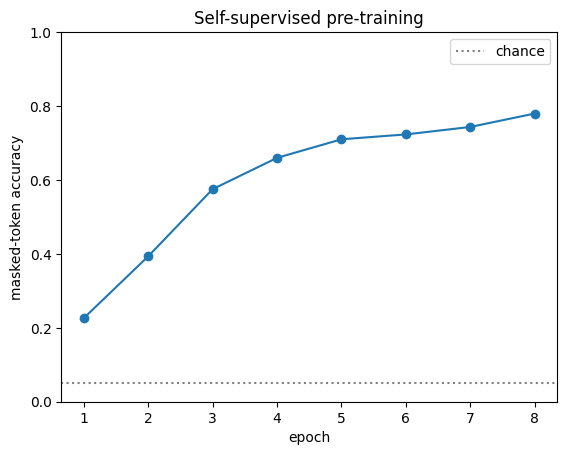

final masked-token accuracy: 0.780 (chance = 0.050)


In [7]:
encoder = Encoder().to(device)
mlm = MLMHead(encoder).to(device)
opt = torch.optim.Adam(mlm.parameters(), 3e-3)
crit = nn.CrossEntropyLoss(ignore_index=-100)
loader = DataLoader(TensorDataset(torch.from_numpy(X_train)), batch_size=128, shuffle=True)

hist = []
for epoch in range(8):
    mlm.train()
    for (xb,) in loader:
        xb = xb.to(device); xin, lab = mask_batch(xb)
        opt.zero_grad(); out = mlm(xin)
        crit(out.reshape(-1, out.size(-1)), lab.reshape(-1)).backward(); opt.step()
    # masked-token accuracy on the test set
    mlm.eval()
    with torch.no_grad():
        xin, lab = mask_batch(torch.from_numpy(X_test).to(device)); out = mlm(xin)
        mm = lab.reshape(-1) != -100
        acc = (out.reshape(-1, out.size(-1)).argmax(1)[mm] == lab.reshape(-1)[mm]).float().mean().item()
    hist.append(acc)

plt.plot(range(1, 9), hist, 'o-'); plt.axhline(1/V, ls=':', color='gray', label='chance')
plt.xlabel('epoch'); plt.ylabel('masked-token accuracy'); plt.ylim(0, 1); plt.legend()
plt.title('Self-supervised pre-training'); plt.show()
print(f"final masked-token accuracy: {hist[-1]:.3f} (chance = {1/V:.3f})")
pretrained_state = {k: v.clone() for k, v in encoder.state_dict().items()}   # save for Part 3

The model learns to fill in masked tokens well above chance — it has discovered the per-topic transition structure, purely from the sequences themselves.

### The payoff: does the representation transfer?

Freeze the encoder and train a **linear probe** to predict the topic from its mean-pooled features. We compare the **pre-trained** encoder against an **untrained** one, at several *small* labelled-set sizes (the realistic setting: lots of unlabelled data, few labels).

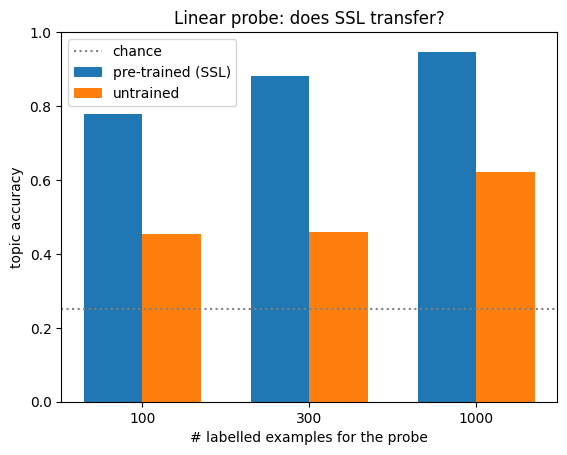

    100 labels -> SSL 0.779 | untrained 0.453
    300 labels -> SSL 0.880 | untrained 0.460
   1000 labels -> SSL 0.946 | untrained 0.621


In [8]:
def features(enc, X):
    enc.eval()
    with torch.no_grad():
        return enc(torch.from_numpy(X).to(device)).mean(1).cpu().numpy()

def probe_accuracy(enc, n_lab):
    Ftr = features(enc, X_train[:n_lab]); Fte = features(enc, X_test)
    clf = LogisticRegression(max_iter=2000).fit(Ftr, y_train[:n_lab])
    return clf.score(Fte, y_test)

ssl_enc = Encoder().to(device); ssl_enc.load_state_dict(pretrained_state)   # pre-trained
rnd_enc = Encoder().to(device)                                              # untrained

label_sizes = [100, 300, 1000]
ssl = [probe_accuracy(ssl_enc, n) for n in label_sizes]
rnd = [probe_accuracy(rnd_enc, n) for n in label_sizes]

x = np.arange(len(label_sizes)); w = 0.35
plt.bar(x - w/2, ssl, w, label='pre-trained (SSL)')
plt.bar(x + w/2, rnd, w, label='untrained')
plt.axhline(1/K, ls=':', color='gray', label='chance')
plt.xticks(x, [str(n) for n in label_sizes]); plt.xlabel('# labelled examples for the probe')
plt.ylabel('topic accuracy'); plt.ylim(0, 1); plt.legend(); plt.title('Linear probe: does SSL transfer?')
plt.show()
for n, a, b in zip(label_sizes, ssl, rnd):
    print(f"  {n:5d} labels -> SSL {a:.3f} | untrained {b:.3f}")

**What is your judgment?** With only 100 labels the SSL encoder is already far ahead of the untrained one. The self-supervised objective — using *no labels* — produced features that make the downstream task easy. That is representation learning working.

# Part 3 — Adapting the frozen model: feature extraction, fine-tuning, and LoRA

Treat the pre-trained encoder as a small **foundation model** and adapt it to the topic-classification task three ways, watching **accuracy vs trainable parameters**.

In [9]:
class Classifier(nn.Module):
    def __init__(self, enc, d=64, k=K):
        super().__init__(); self.enc = enc; self.head = nn.Linear(d, k)
    def forward(self, x): return self.head(self.enc(x).mean(1))

def train_classifier(model, n_lab=1000, epochs=12, lr=3e-3):
    model = model.to(device)
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.Adam(params, lr)
    loader = DataLoader(TensorDataset(torch.from_numpy(X_train[:n_lab]), torch.from_numpy(y_train[:n_lab])),
                        batch_size=64, shuffle=True)
    for _ in range(epochs):
        model.train()
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad(); F.cross_entropy(model(xb), yb).backward(); opt.step()
    model.eval()
    with torch.no_grad():
        acc = (model(torch.from_numpy(X_test).to(device)).argmax(1) == torch.from_numpy(y_test).to(device)).float().mean().item()
    return acc

def fresh_pretrained_encoder():
    e = Encoder().to(device); e.load_state_dict(pretrained_state); return e

### 1. Feature extraction — freeze the encoder, train only the head

In [10]:
m = Classifier(fresh_pretrained_encoder())
for p in m.enc.parameters(): p.requires_grad = False
acc_fe = train_classifier(m)
print(f"feature extraction: accuracy = {acc_fe:.3f}, trainable params = {n_params(m):,}")

feature extraction: accuracy = 0.771, trainable params = 260


### 2. Full fine-tuning — update everything (the accuracy ceiling, at full cost)

In [11]:
m = Classifier(fresh_pretrained_encoder())
acc_ft = train_classifier(m)
print(f"full fine-tuning : accuracy = {acc_ft:.3f}, trainable params = {n_params(m):,}")

full fine-tuning : accuracy = 0.997, trainable params = 68,548


### 3. LoRA — a low-rank, trainable side-path on frozen weights

For a frozen linear layer $W_0$, LoRA adds a trainable update $\Delta W = BA$ with rank $r \ll d$, so the layer computes $h = W_0x + \tfrac{\alpha}{r}BAx$. We wrap every `nn.Linear` in the encoder and train **only** $A$ and $B$ (plus the head).

In [12]:
class LoRALinear(nn.Module):
    def __init__(self, base: nn.Linear, r=8, alpha=16):
        super().__init__(); self.base = base
        for p in self.base.parameters(): p.requires_grad = False   # freeze W0, b
        d_out, d_in = base.weight.shape
        self.A = nn.Parameter(torch.randn(r, d_in) * 0.01)         # down-project
        self.B = nn.Parameter(torch.zeros(d_out, r))              # up-project (starts at 0)
        self.scale = alpha / r
    def forward(self, x):
        return self.base(x) + self.scale * (x @ self.A.t() @ self.B.t())

def inject_lora(module, r):
    for name, child in module.named_children():
        if isinstance(child, nn.Linear):
            setattr(module, name, LoRALinear(child, r=r))
        else:
            inject_lora(child, r)

m = Classifier(fresh_pretrained_encoder())
for p in m.enc.parameters(): p.requires_grad = False
inject_lora(m.enc, r=8)                       # only the A,B matrices become trainable
acc_lora = train_classifier(m)
print(f"LoRA (r=8)      : accuracy = {acc_lora:.3f}, trainable params = {n_params(m):,}")

LoRA (r=8)      : accuracy = 0.996, trainable params = 14,596


### How does rank $r$ trade parameters for accuracy?

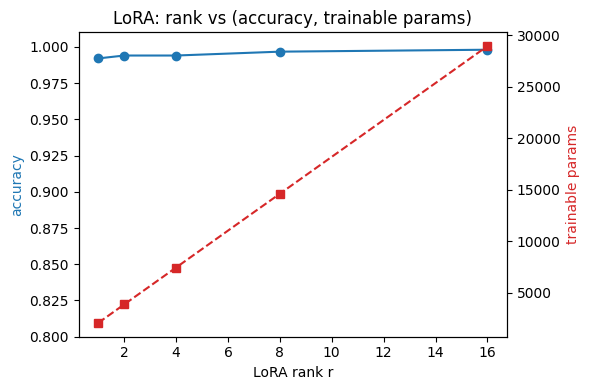

  r= 1: acc=0.992, trainable=2,052
  r= 2: acc=0.994, trainable=3,844
  r= 4: acc=0.994, trainable=7,428
  r= 8: acc=0.997, trainable=14,596
  r=16: acc=0.998, trainable=28,932


In [13]:
ranks, accs, ps = [1, 2, 4, 8, 16], [], []
for r in ranks:
    m = Classifier(fresh_pretrained_encoder())
    for p in m.enc.parameters(): p.requires_grad = False
    inject_lora(m.enc, r=r)
    accs.append(train_classifier(m)); ps.append(n_params(m))

fig, ax1 = plt.subplots(figsize=(6, 4))
ax1.plot(ranks, accs, 'o-', color='tab:blue'); ax1.set_xlabel('LoRA rank r')
ax1.set_ylabel('accuracy', color='tab:blue'); ax1.set_ylim(0.8, 1.01)
ax2 = ax1.twinx(); ax2.plot(ranks, ps, 's--', color='tab:red')
ax2.set_ylabel('trainable params', color='tab:red')
plt.title('LoRA: rank vs (accuracy, trainable params)'); plt.tight_layout(); plt.show()
for r, a, p in zip(ranks, accs, ps): print(f"  r={r:2d}: acc={a:.3f}, trainable={p:,}")

### The library version

From-scratch `LoRALinear` is exactly what the `peft` library does. In the lab you would instead write:

```python
from peft import LoraConfig, get_peft_model
cfg = LoraConfig(r=8, lora_alpha=16,
                 target_modules=["wq", "wv"],   # which Linear layers to adapt
                 task_type="SEQ_CLS")
model = get_peft_model(base_model, cfg)
model.print_trainable_parameters()
```

### Summary: accuracy vs cost

In [15]:
full = n_params(Classifier(fresh_pretrained_encoder()))   # all params trainable
rows = [("feature extraction", acc_fe, 260),
        ("full fine-tuning",   acc_ft, full),
        ("LoRA (r=2)",         acc_lora, ps[ranks.index(2)])]
print(f"{'strategy':22s}{'accuracy':>10s}{'trainable':>12s}{'% of full':>11s}")
for name, a, p in rows:
    print(f"{name:22s}{a:>10.3f}{p:>12,}{100*p/full:>10.1f}%")

strategy                accuracy   trainable  % of full
feature extraction         0.771         260       0.4%
full fine-tuning           0.997      68,548     100.0%
LoRA (r=2)                 0.996       3,844       5.6%


# Wrap-up

- **Contextual > static** (Part 1): a Transformer embedding adapts to context; GloVe cannot.
- **Self-supervision** (Part 2): masked-token prediction learns a representation with *no labels* that transfers — a linear probe recovers the topic from very few labels, while an untrained encoder cannot.
- **Adaptation** (Part 3): feature extraction is cheapest but weakest; full fine-tuning is best but updates everything; **LoRA** reaches near-fine-tuning accuracy while training a tiny fraction of the parameters, with rank $r$ as the accuracy/size dial.